# E3 clDice

Une perte qui compare les **lignes centrales** des racines (clDice, Shit et al., CVPR 2021) réduit-elle les racines coupées et améliore-t-elle la longueur ? Le Dice est dominé par les grosses racines : un trou dans une racine de 20 px de large coûte dix fois plus qu'un trou de même longueur dans une racine de 2 px. clDice compte la longueur de ligne centrale manquée, quelle que soit la largeur.

**L'essentiel** : non, sur ces masques. Essai arrêté à l'époque 50 : le Dice global du val reste en dessous de l'essai sans clDice aux mêmes époques (0,735 contre 0,746 à l'époque 50), et son meilleur score (0,736) est loin de celui du notebook 04 (0,762). Cause probable : les fentes des masques PRMI coupent leurs lignes centrales, et clDice pénalise un modèle qui relie les morceaux. D'où le comblement des fentes (notebook A2).

Seule la perte change par rapport au notebook 04 (1 000 images, 150 époques au plus, augmentation) :
- avant : 0,5 x BCE + 0,5 x Dice ;
- ici : 0,5 x BCE + 0,5 x (0,5 x Dice + 0,5 x clDice), clDice calculé carré par carré sur les carrés avec racine.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import pandas as pd
from scipy import ndimage as ndi

from prmi import viz
from prmi.dataset import VAL_LARGE, RootCrops, draw_extra, load_extra, load_lot, to_display
from prmi.diagnostic import overlay_mask
from prmi.train import (compare_runs, load_run, predict, run_exists, score_run, soft_skeleton, summarize, train,
                        train_eval_items)

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

NAME = 'unet_effb0_1000_cldice'
BASE = 'unet_effb0_1000'                   # notebook 04 : même entraînement, sans clDice
OTHERS = ['unet_effb0_s2_aug', 'unet_effb0_s2_aug_origine']   # notebook 03 et essai E1, pour le grand val
SCALE = 2
N_EXTRA = 851
CROPS_PER_EPOCH = 298
EPOCHS = 150
CLDICE = 0.5                               # poids du clDice dans la part Dice de la perte
N_VAL_LARGE = 1000

## 1. Ce que voit clDice

Le squelette « doux » est calculé par érosions successives (10 itérations), il reste dérivable. clDice compare le squelette de la prédiction au masque de référence, et le squelette de la référence à la prédiction.

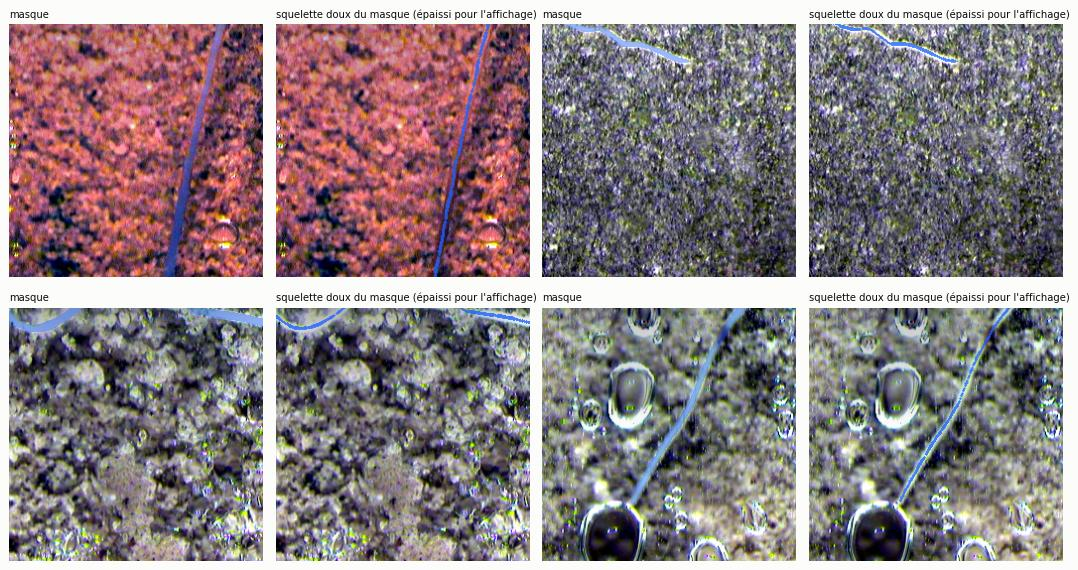

In [2]:
clean = load_lot('train', SCALE)
crops = RootCrops(clean, seed=3)
pairs = [crops[i] for i in range(0, 120, 10) if crops[i][1].mean() > 0.01][:4]
images, titles = [], []
for x, y in pairs:
    skel = soft_skeleton(y[None])[0, 0].numpy()
    images += [overlay_mask(to_display(x), y[0].numpy() > 0), overlay_mask(to_display(x), ndi.binary_dilation(skel > 0.5), alpha=0.8)]
    titles += ['masque', 'squelette doux du masque (épaissi pour l\'affichage)']
viz.image_grid(images, titles, ncols=4);

## 2. Données (identiques au notebook 04)

In [3]:
extra = draw_extra(N_EXTRA)                         # même tirage que le notebook 04 (relu)
train_items = clean + load_extra(extra, SCALE, filled=False)   # masques d'origine bruts
val_items = load_lot('val', SCALE)
val_large = draw_extra(N_VAL_LARGE, path=VAL_LARGE, split='val')
print('train', len(train_items), 'images ; val corrigé', len(val_items), '; grand val', len(val_large),
      f"({val_large['has_root'].sum()} avec racine, {val_large['tube_id'].nunique()} tubes)")

train 1000 images ; val corrigé 74 ; grand val 1000 (568 avec racine, 8 tubes)


## 3. Entraînement

Arrêté à la main à l'époque 50 (environ 2 h prévues au total) : le résultat ne rattrapait pas l'essai sans clDice. Les cellules suivantes relisent l'essai enregistré.

In [1]:
if run_exists(NAME):
    print('Entraînement déjà présent, relecture de', NAME)
else:
    train(train_items, val_items, NAME, epochs=EPOCHS, patience=20, augment=True, crops_per_epoch=CROPS_PER_EPOCH,
          train_eval=train_eval_items(clean), cldice=CLDICE)

NameError: name 'run_exists' is not defined

,epoch,lr,lr_encoder,train_loss,train_dice,dice,global_dice,roots_found,ghosts,length_err,fp_empty,cldice,global_cldice,val_loss,seconds
42,43,0.000819,0.000082,0.185001,0.703311,0.684759,0.73628,0.809524,50,0.160656,0.5,0.795372,0.845765,0.118262,51.262768


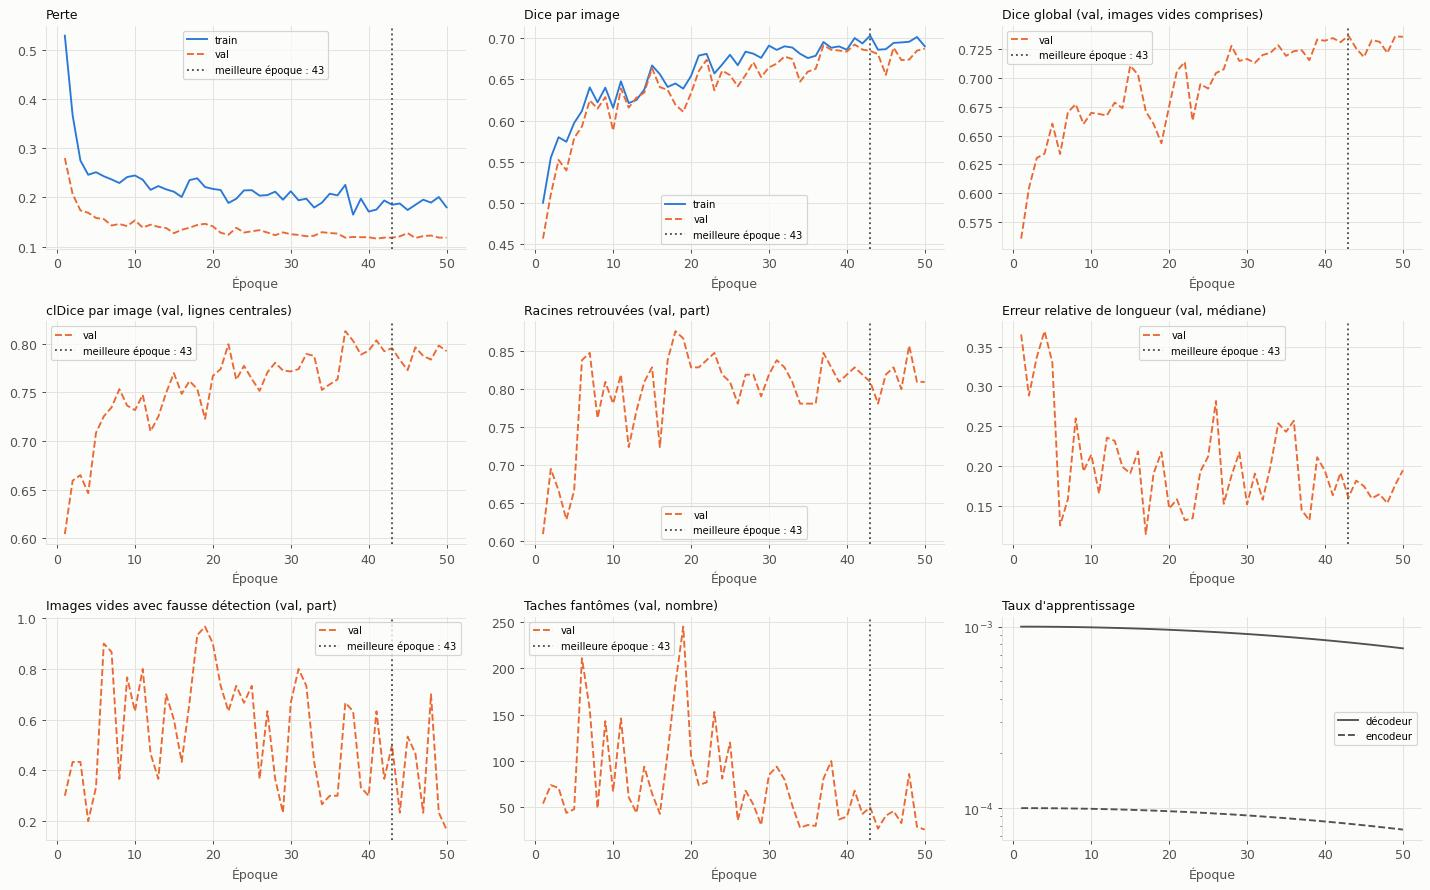

In [2]:
model, history, best_epoch, per_image = load_run(NAME)
device = next(model.parameters()).device
viz.plot_history(history, best_epoch);
history.loc[history['epoch'] == best_epoch]

## 4. Val corrigé : clDice contre sans clDice

Époque par époque, puis image par image à la meilleure époque de chaque essai (écart = clDice moins sans clDice ; pour l'erreur de longueur, un écart négatif est un progrès).

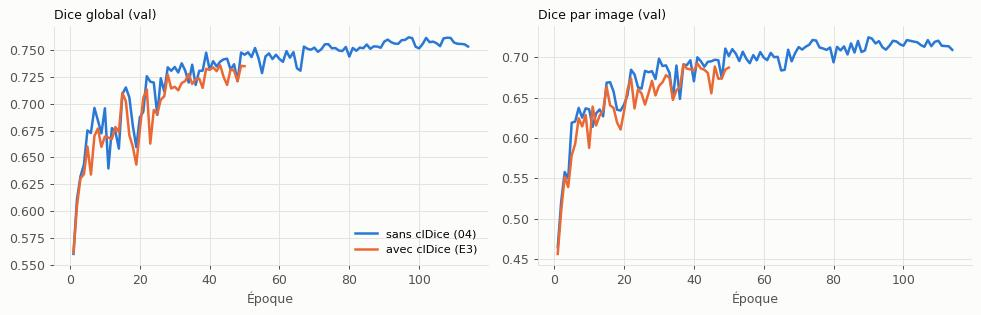

In [3]:
fig = viz.plot_history_pair({'sans clDice (04)': load_run(BASE)[1], 'avec clDice (E3)': history}, ['global_dice', 'dice'])
viz.save(fig, 'E3_cldice_contre_sans.png')

In [4]:
rows = {}
for metric in ['dice', 'cldice', 'length_err']:
    summary, paired, _ = compare_runs(BASE, NAME, metric)
    rows[metric] = paired
display(summary.round(3))
pd.DataFrame(rows).T.round(4)

,dice,global_dice,roots_found,ghosts,length_err,fp_empty,cldice,global_cldice
unet_effb0_1000,0.698,0.765,0.798,29.0,0.157,0.357,0.796,0.860
unet_effb0_1000_cldice,0.666,0.739,0.781,42.0,0.181,0.500,0.774,0.848


,images,écart moyen,écart médian,b meilleur,b moins bon,p (Wilcoxon)
dice,46.0,-0.0318,-0.0257,9.0,36.0,0.0004
cldice,46.0,-0.0227,-0.0073,16.0,29.0,0.0405
length_err,46.0,0.0158,0.0302,15.0,31.0,0.1270


## 5. Grand val

Non évalué : essai arrêté avant la fin.

In [ ]:
runs = OTHERS + [BASE, NAME]
large = {n: score_run(n, val_large, 'val_large_images.csv', filled=False) for n in runs}   # masques d'origine bruts
display(pd.DataFrame({n: summarize(t) for n, t in large.items()}).T.round(3))

rows = {}
for metric in ['dice', 'cldice', 'length_err']:
    rows[metric] = compare_runs(BASE, NAME, metric, 'val_large_images.csv')[1]
pd.DataFrame(rows).T.round(4)

## 6. Images

Val corrigé au curseur : référence à gauche, prédiction avec clDice à droite.

In [ ]:
preds = {it['name']: predict(model, it, device) for it in val_items}
viz.browse_predictions(val_items, preds, per_image)

## 7. À retenir

- **clDice ne fait pas mieux** : Dice global du val en dessous de l'essai sans clDice à 39 époques sur 50 (Dice par image : 43 sur 50).
- **À la meilleure époque de chaque essai** : -0,032 de Dice par image (36 images sur 46 moins bonnes, p < 0,001), clDice par image lui-même en baisse (-0,023), et plus de fausses détections (50 % des images vides touchées contre 36 %).
- **Cause probable** : les fentes entre rectangles des masques PRMI coupent les lignes centrales de référence ; clDice récompense alors un modèle qui coupe les racines comme les rectangles.
- **Suite** : combler les fentes (notebook A2) avant d'envisager à nouveau clDice.